In [ ]:
import spacy
import pandas as pd
import numpy as np
import math
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

## Term-Document Matrices and TF-IDF

**Consider the following mini-corpus of four short documents:
D1: “The Red Sox won at Fenway last night.”
D2: “Fenway Park is the oldest ballpark in the American League.”
D3: “The Yankees defeated the Red Sox in extra innings.”
D4: “Extra innings make baseball exciting for every fan.”**


**(a) After applying standard pre-processing steps (lowercasing, stop-word removal, and
lemmatization using spaCy), construct the raw-count Term-Document Matrix (TDM)
for this corpus. Present the resulting matrix as a table with terms as rows and doc-
uments as columns**

In [ ]:
from collections import Counter
import pandas as pd
import spacy
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
    nlp = spacy.load("en_core_web_sm")

documents = {
    "D1": "The Red Sox won at Fenway last night.",
    "D2": "Fenway Park is the oldest ballpark in the American League.",
    "D3": "The Yankees defeated the Red Sox in extra innings.",
    "D4": "Extra innings make baseball exciting for every fan."
}

processed_docs = {}
for doc_id, text in documents.items():
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and token.lemma_.strip()
    ]
    processed_docs[doc_id] = tokens

unique_terms = set()
for tokens in processed_docs.values():
    unique_terms.update(tokens)
all_terms = sorted(list(unique_terms))

# tdm
tdm_data = {}
for doc_id, terms in processed_docs.items():
    counts = Counter(terms)
    tdm_data[doc_id] = [counts[term] for term in all_terms]

# display data
tdm_df = pd.DataFrame(tdm_data, index=all_terms)
tdm_df

,D1,D2,D3,D4
american,0,1,0,0
ballpark,0,1,0,0
baseball,0,0,0,1
defeat,0,0,1,0
exciting,0,0,0,1
extra,0,0,1,1
fan,0,0,0,1
fenway,1,1,0,0
innings,0,0,1,1
league,0,1,0,0


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

texts = list(documents.values())

vec = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

X = vec.fit_transform(texts)

print("Matrix shape:", X.shape)
print("Example features:", vec.get_feature_names_out()[:10])

Matrix shape: (4, 7)
Example features: ['extra' 'extra innings' 'fenway' 'innings' 'red' 'red sox' 'sox']


**(b) Compute the TF-IDF weight for the term fenway in document D1 and in docu-
ment D2 using the standard IDF formula:
IDF(t) = log
 N
dft

,
where N is the total number of documents and dft is the number of documents
containing term t. Use the raw-count TF variant (TF = raw count). Show all
arithmetic steps**

In [ ]:
import math
N = 4
df_t = 2

idf = math.log10(N / df_t)

# raw count TF
tf_d1 = tdm_df.loc['fenway', 'D1']
tf_d2 = tdm_df.loc['fenway', 'D2']

tf_idf_d1 = tf_d1 * idf
tf_idf_d2 = tf_d2 * idf

print("TF-IDF for 'fenway' in D1:", tf_idf_d1)
print("TF-IDF for 'fenway' in D2:", tf_idf_d2)

TF-IDF for 'fenway' in D1: 0.3010299956639812
TF-IDF for 'fenway' in D2: 0.3010299956639812


**(c) Explain the conceptual difference between TF Variation 3 (relative frequency, TF =
count/total words) and TF Variation 4 (log scaling, TF = log(1 + count)). In which
social-science scenario would you prefer log scaling over raw counts, and why**

TF Variation 3 measures proportion while TF Variation 4 compresses the scale of word counts. The social science scenario I would use TF Variation 4 (Log Scaling) over raw counts or relative frequency when analyzing highly repetitive political rhetoric, propaganda, or campaigns.

##2. Comparing Groups with Bag-of-Words Lean

**You are given two collections of tweets: 100 tweets from supporters of Candidate A and
100 tweets from supporters of Candidate B. After pre-processing, you compute a lean
score for each word using:
Lean(t) = countA(t) − countB (t)**

**(a) Write a Python function compute lean(bag a, bag b) that accepts two lists of
lemmatized tokens, builds frequency counts for each group, and returns a pandas
DataFrame with columns [‘term’, ‘count a’, ‘count b’, ‘lean’] sorted by
absolute lean (descending). Include the complete code in your notebook.**

In [ ]:
from collections import Counter
import pandas as pd

def compute_lean(bag_a, bag_b):
    counts_a = Counter(bag_a)
    counts_b = Counter(bag_b)

    all_terms = set(counts_a.keys()).union(set(counts_b.keys()))

    data = []
    for term in all_terms:
        count_a = counts_a.get(term, 0)
        count_b = counts_b.get(term, 0)
        lean = count_a - count_b
        data.append({
            'term': term,
            'count_a': count_a,
            'count_b': count_b,
            'lean': lean
        })

    df = pd.DataFrame(data, columns=['term', 'count_a', 'count_b', 'lean'])

    df['abs_lean'] = df['lean'].abs()
    df = df.sort_values(by='abs_lean', ascending=False).drop(columns=['abs_lean']).reset_index(drop=True)

    return df

# used random words for the sample
sample_bag_a = ['election', 'reform', 'freedom', 'jobs', 'tax', 'economy', 'healthcare']
sample_bag_b = ['healthcare', 'economy', 'insurance', 'housing', 'rights', 'tax']

result_df = compute_lean(sample_bag_a, sample_bag_b)
display(result_df)

,term,count_a,count_b,lean
0,election,1,0,1
1,freedom,1,0,1
2,jobs,1,0,1
3,insurance,0,1,-1
4,reform,1,0,1
5,rights,0,1,-1
6,housing,0,1,-1
7,economy,1,1,0
8,healthcare,1,1,0
9,tax,1,1,0


**(b) A classmate points out that the lean score only works reliably when the two corpora
are roughly the same size. Propose a normalised version of the lean score that
accounts for corpus-size differences, and write the formula explicitly.**

When the corpora are both different in size, they are biased towards the larger corpus. We can solve this by dividing the tokens with the corpus.

$$\text{Lean}_{\text{normalized}}(t) = \frac{count_A(t)}{N_A} - \frac{count_B(t)}{N_B}$$


**(c) Identify and explain one additional limitation of the lean approach that normalisation alone cannot fix. Suggest a TF-IDF-based alternative that addresses this limitation.**


A limitation is its inability to distinguish word importance. Normalization cleans up the tokens but it doesn't change how much each token matters.

A TF-IDF based alternative to address this limitation is cosine similiarity.

##3. Cosine Similarity and Document Distance

You have vectorised three political speeches (S1, S2, S3) using TF-IDF and obtained the
following simplified 4-dimensional vectors over vocabulary {economy, freedom, healthcare,
tax }:
S1 = [0.8, 0.1, 0.5, 0.3], S2 = [0.7, 0.2, 0.4, 0.4], S3 = [0.1, 0.9, 0.1, 0.0].

(a) Manually compute the cosine similarity between S1 and S2, and between S1 and S3:
cos(u, v) = u · v
∥u∥ ∥v∥.
Show all arithmetic steps

In [ ]:
import numpy as np

S1 = np.array([0.8, 0.1, 0.5, 0.3])
S2 = np.array([0.7, 0.2, 0.4, 0.4])
S3 = np.array([0.1, 0.9, 0.1, 0.0])

def cosine_similarity(u, v):
    dot_product = np.dot(u, v)
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    return dot_product / (norm_u * norm_v)

cos_s1_s2 = cosine_similarity(S1, S2)
cos_s1_s3 = cosine_similarity(S1, S3)

print("Cosine Similarity between S1 and S2:", cos_s1_s2)
print("Cosine Similarity between S1 and S3:", cos_s1_s3)

Cosine Similarity between S1 and S2: 0.9811049102515929
Cosine Similarity between S1 and S3: 0.2426979105178816


(b) Using scikit-learn, write Python code that (i) constructs a TF-IDF matrix from
at least five short example texts of your choosing, (ii) computes the full pairwise
cosine similarity matrix, and (iii) visualises the matrix as a heatmap using seaborn

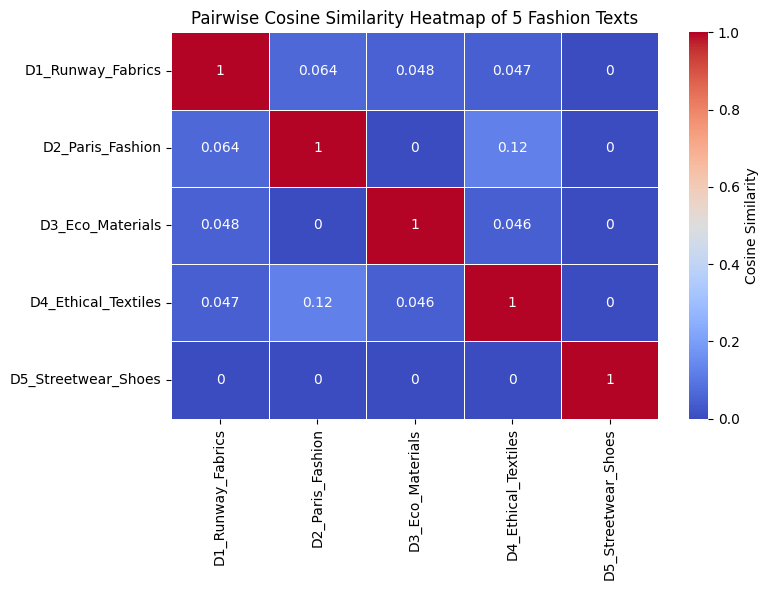

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

example_texts = [
    "The designer presented an elegant autumn collection featuring sustainable luxury fabrics on the runway.",
    "Top fashion houses highlighted minimalist silk dresses and luxury tailoring at Paris Fashion Week.",
    "Sustainable apparel brands are using organic cotton and recycled materials to reduce waste.",
    "Eco-friendly textiles like linen and hemp are key to ethical fashion and sustainable garments.",
    "These vintage leather boots and retro sneakers are trending in casual streetwear footwear."
]

doc_labels = [
    "D1_Runway_Fabrics",
    "D2_Paris_Fashion",
    "D3_Eco_Materials",
    "D4_Ethical_Textiles",
    "D5_Streetwear_Shoes"
]

# use tf-idf to vectorize!!!
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(example_texts)

# (ii)
cosine_sim_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)

# seaborn
cosine_sim_df = pd.DataFrame(cosine_sim_matrix, index=doc_labels, columns=doc_labels)

# (iii)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cosine_sim_df,
    annot=True,
    cmap="coolwarm",
    vmin=0.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={'label': 'Cosine Similarity'}
)
plt.title("Pairwise Cosine Similarity Heatmap of 5 Fashion Texts")
plt.tight_layout()
plt.show()

(c) Describe one substantive social-science research question for which measuring cosine
similarity between documents is methodologically appropriate. Justify your choice
of cosine similarity over Euclidean distance

Cosine similarity is superior when measuring political manifestos or party platforms due to the text length. By using cosine similarity, social scientists can accurately track whether party platforms are converging or diverging ideologically over time without their data being corrupted by text length. Euclidean's weakness is that if you use two documents, one that is lengthy and one that is not, these will mathmatically appear distant even though they could have the same policies or focus.

##4. K-Means Clustering and Cluster Validation

You have collected 200 BBC news articles and wish to cluster them into thematic groups
using K-Means.

(a) Outline the four algorithmic steps of K-Means as taught in class (Initialize → Assign
→ Refine → Repeat). Explain what convergence means in this context and why the
algorithm is not guaranteed to find the globally optimal solution.

1. Initialize: pick starting points for K data points

2. Assign: Go through every data point in dataset, calculate distance using Euclidean distance. Assign the data point to the cluster represented by the closest centroid.

3. Refine: Calculate the mean of all the data points assigned to that cluster

4. Repeat: Reassign all data points to their nearest new centroid and recalculate the positions of K


Convergence means the algorithm has finished, or converged. The assignments no longer change significantly between iterations.

(b) Write Python code that: (i) vectorises the articles using TF-IDF, (ii) fits K-Means
for K ∈ {2, 3, 4, 5, 6}, (iii) plots the Within-Cluster Sum of Squares (WCSS) to
produce an elbow plot, and (iv) computes the silhouette score for each K. Based
on your plots, select and justify an optimal K. You may use a publicly available
dataset (e.g., the 20 Newsgroups dataset via sklearn.datasets) as a stand-in

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

DATA_URL = "https://huggingface.co/datasets/SetFit/bbc-news/resolve/main/bbc-text.csv"
df_raw = pd.read_csv(DATA_URL)
df_raw = df_raw.dropna(subset=["text","category"]).copy()
df_raw["category"] = df_raw["category"].astype(str)

N_PER_CAT = 50
parts = [df_raw[df_raw["category"]==c].sample(n=N_PER_CAT, random_state=RANDOM_STATE)
         for c in sorted(df_raw["category"].unique())]
mini = pd.concat(parts, ignore_index=True)

def simple_clean(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

texts = mini["text"].apply(simple_clean).tolist()
labels = mini["category"].tolist()

print("Ready! Dataset shape:", mini.shape)
mini.head(3)

Ready! Dataset shape: (250, 2)


,category,text
0,business,irish company hit by iraqi report shares in ir...
1,business,bat spit drug firm goes to market a german fir...
2,business,electronics firms eye plasma deal consumer ele...


In [ ]:
vec = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

X = vec.fit_transform(texts)

print("Matrix shape:", X.shape)
print("Example features:", vec.get_feature_names_out()[100:110])

Matrix shape: (250, 7026)
Example features: ['20 year' '200' '200 000' '200 million' '2000' '2001' '2001 mr' '2002'
 '2003' '2003 emerged']


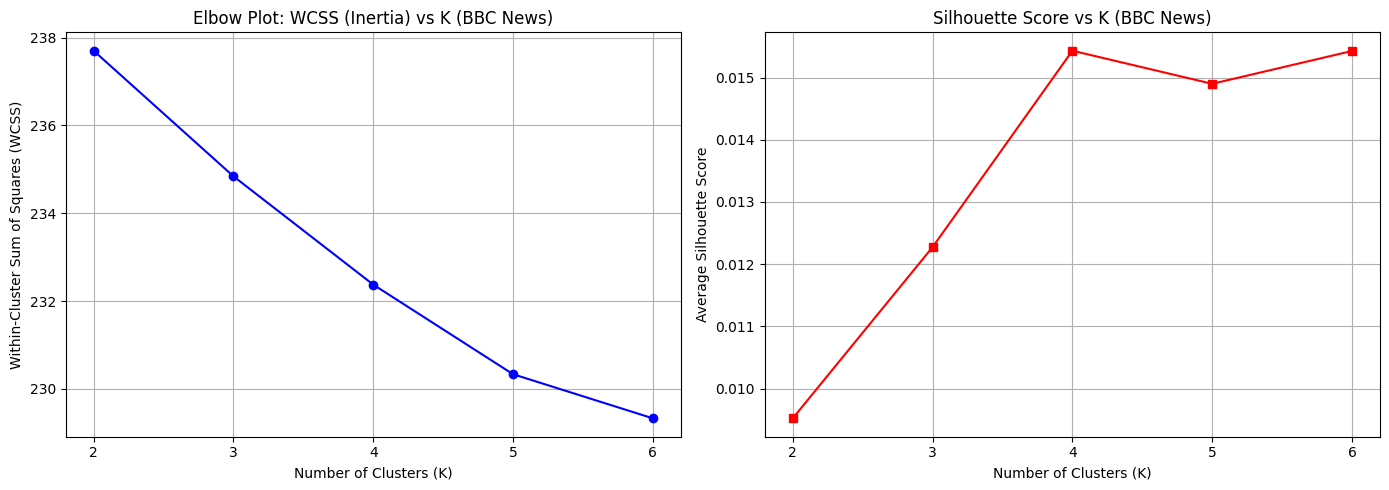

K = 2 | WCSS (Inertia): 237.7024 | Silhouette Score: 0.0095
K = 3 | WCSS (Inertia): 234.8412 | Silhouette Score: 0.0123
K = 4 | WCSS (Inertia): 232.3737 | Silhouette Score: 0.0154
K = 5 | WCSS (Inertia): 230.3323 | Silhouette Score: 0.0149
K = 6 | WCSS (Inertia): 229.3276 | Silhouette Score: 0.0154


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_range = list(range(2, 7))
inertia_scores = []
silhouette_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE)
    cluster_labels = km.fit_predict(X)

    inertia_scores.append(km.inertia_)

    score = silhouette_score(X, cluster_labels, random_state=RANDOM_STATE)
    silhouette_scores.append(score)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# elbow plot WCSS
ax1.plot(K_range, inertia_scores, marker='o', color='b', linestyle='-')
ax1.set_title("Elbow Plot: WCSS (Inertia) vs K (BBC News)")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("Within-Cluster Sum of Squares (WCSS)")
ax1.set_xticks(K_range)
ax1.grid(True)

# silhouette score plot
ax2.plot(K_range, silhouette_scores, marker='s', color='r', linestyle='-')
ax2.set_title("Silhouette Score vs K (BBC News)")
ax2.set_xlabel("Number of Clusters (K)")
ax2.set_ylabel("Average Silhouette Score")
ax2.set_xticks(K_range)
ax2.grid(True)

plt.tight_layout()
plt.show()

for k, wcss, sil in zip(K_range, inertia_scores, silhouette_scores):
    print(f"K = {k} | WCSS (Inertia): {wcss:.4f} | Silhouette Score: {sil:.4f}")

##5. Sentiment Analysis — Lexicon Methods

Using the VADER sentiment analyser (available via nltk) and any publicly available
dataset of your choice (e.g., IMDB reviews, Amazon product reviews, or tweets), complete
the following tasks.

(a) Apply VADER to compute a compound sentiment score for each document. Plot the
distribution of scores. Then compare your VADER scores against a simple positive-
word-count method using a binary lexicon of your choice (e.g., the Bing lexicon
via nltk’s opinion lexicon). Discuss any notable divergences between the two
methods

In [ ]:
!pip install -q afinn nrclex nltk wordcloud seaborn matplotlib pandas numpy

import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.sentiment import SentimentIntensityAnalyzer
from collections import Counter

from afinn import Afinn
from nrclex import NRCLex
from wordcloud import WordCloud

# Download NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)

True

In [ ]:
# tom holland spiderman movies on letterboxd
reviews = [
    # Homecoming reviews
    "Holland's take on the character has grown to become my favorite, and the rest of the cast is great too.",
    "Better than I remember. Funny, cute, exciting.",

    # Far from home reviews
    "Not the best idea for a Spiderman movie.",
    "This movie has some of my top Tom Holland moments as Spiderman but does also have some lows. This movie for sure beats homecoming.",

    # No way home reviews
    "everything’s just downhill after this yall it’s so sad.",
    "In terms of pure comic book movie experience, this one is up there as one of the best.",

    # Brand new day reviews
    "This is a very fun ride, but some moments feel more like intentional plots devices than character choices.",
    "This was ok. Kind of uninspired. While it was a decent movie, some parts of it kinda felt like the plot was using them for their convenience."
]

# character labels for each review
characters = [
    "Homecoming", "Homecoming",
    "Far From Home", "Far From Home",
    "No Way Home", "No Way Home",
    "Brand New Day", "Brand New Day"
]

print(f"Loaded {len(reviews)} Tom Holland Spiderman Movies Reviews")
print(f"Characters: {', '.join(set(characters))}")

Loaded 8 Tom Holland Spiderman Movies Reviews
Characters: Homecoming, Far From Home, No Way Home, Brand New Day


In [ ]:
def preprocess_text(text, remove_stopwords=True):
    """
    Tokenize and clean text for word-level sentiment analysis.

    Args:
        text: String to process
        remove_stopwords: Boolean, whether to remove stopwords

    Returns:
        List of cleaned tokens (lowercase, alphabetic only)
    """
    # tokenize
    tokens = word_tokenize(text.lower())

    # keep only alphabetic tokens (removes punctuation, numbers)
    tokens = [token for token in tokens if token.isalpha()]

    # remove stopwords
    if remove_stopwords:
        stop_words = set(stopwords.words('english'))
        tokens = [token for token in tokens if token not in stop_words]

    return tokens

# test function
sample = "Better than I remember. Funny, cute, exciting."
print("Original:", sample)
print("Tokens (with stopwords removed):", preprocess_text(sample, remove_stopwords=True))
print("Tokens (with stopwords kept):", preprocess_text(sample, remove_stopwords=False))

Original: Better than I remember. Funny, cute, exciting.
Tokens (with stopwords removed): ['better', 'remember', 'funny', 'cute', 'exciting']
Tokens (with stopwords kept): ['better', 'than', 'i', 'remember', 'funny', 'cute', 'exciting']


In [ ]:
# initialize AFINN and VADER
afinn = Afinn()
sia = SentimentIntensityAnalyzer()

# create DataFrame
df = pd.DataFrame({
    'character': characters,
    'review': reviews
});

# calculate sentiment scores
df['afinn_score'] = df['review'].apply(lambda x: afinn.score(x))
df['vader_compound'] = df['review'].apply(lambda x: sia.polarity_scores(x)['compound'])

# add review ID for easier reference
df['review_id'] = range(1, len(df) + 1)

# display results
print("Sentiment Scores for All Reviews:")
print("=" * 100)
display_df = df[['review_id', 'character', 'afinn_score', 'vader_compound']].copy()
print(display_df.to_string(index=False))

print("\n" + "="*100)
print("Sample reviews with scores:")
print("="*100)
for idx, row in df.head(3).iterrows():
    print(f"\nReview {row['review_id']}: {row['character']}")
    print(f"Text: {row['review'][:70]}...")
    print(f"AFINN: {row['afinn_score']:+.1f}  |  VADER: {row['vader_compound']:+.3f}")

Sentiment Scores for All Reviews:
 review_id     character  afinn_score  vader_compound
         1    Homecoming          5.0          0.7964
         2    Homecoming         11.0          0.9001
         3 Far From Home          3.0         -0.5216
         4 Far From Home          2.0          0.2846
         5   No Way Home         -2.0         -0.6113
         6   No Way Home          5.0          0.6369
         7 Brand New Day          6.0          0.7172
         8 Brand New Day          0.0          0.5302

Sample reviews with scores:

Review 1: Homecoming
Text: Holland's take on the character has grown to become my favorite, and t...
AFINN: +5.0  |  VADER: +0.796

Review 2: Homecoming
Text: Better than I remember. Funny, cute, exciting....
AFINN: +11.0  |  VADER: +0.900

Review 3: Far From Home
Text: Not the best idea for a Spiderman movie....
AFINN: +3.0  |  VADER: -0.522


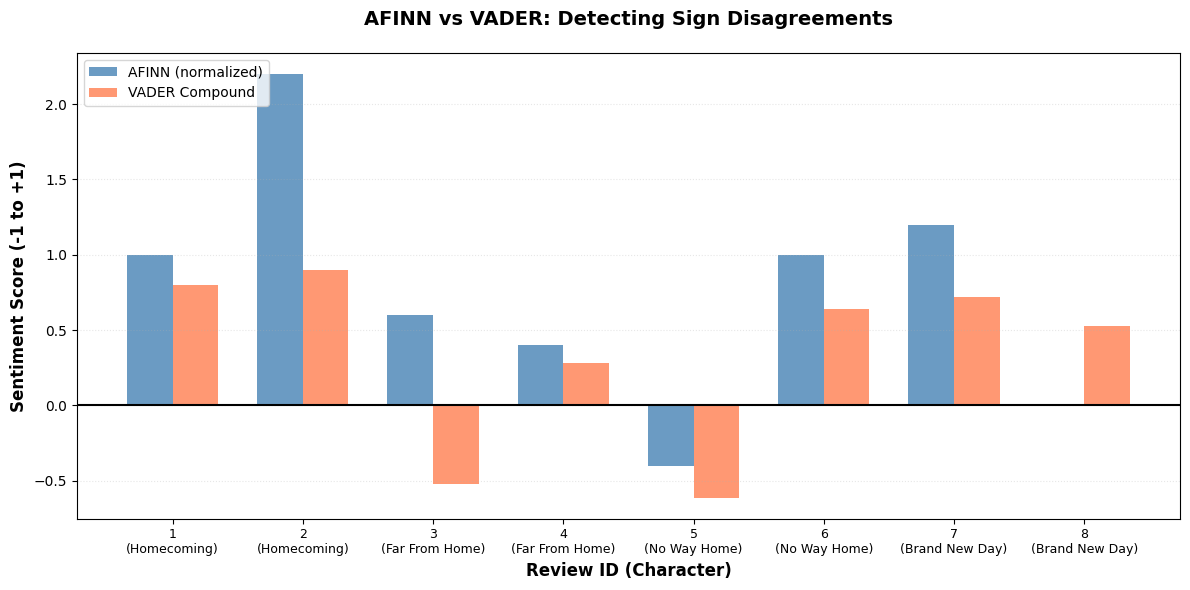


DETECTING SIGN DISAGREEMENTS (Positive vs. Negative):

Found 1 review(s) where AFINN and VADER chose OPPOSITE signs:

--- DISAGREEMENT FOUND: Review 3 (Far From Home) ---
Text: "Not the best idea for a Spiderman movie."
AFINN (normalized): +0.600 [Direction: Positive]
VADER Compound:     -0.522 [Direction: Negative]
------------------------------------------------------------
EXPLANATION: This usually happens because of negation (e.g., 'not bad') or context.

Full Review Summary Table:
 review_id     character  afinn_normalized  vader_compound  disagreement
         1    Homecoming               1.0          0.7964         False
         2    Homecoming               2.2          0.9001         False
         3 Far From Home               0.6         -0.5216          True
         4 Far From Home               0.4          0.2846         False
         5   No Way Home              -0.4         -0.6113         False
         6   No Way Home               1.0          0.6369         Fal

In [ ]:
!pip install -q afinn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from afinn import Afinn
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)

reviews = [
    "Holland's take on the character has grown to become my favorite, and the rest of the cast is great too.",
    "Better than I remember. Funny, cute, exciting.",
    "Not the best idea for a Spiderman movie.",
    "This movie has some of my top Tom Holland moments as Spiderman but does also have some lows. This movie for sure beats homecoming.",
    "everything’s just downhill after this yall it’s so sad.",
    "In terms of pure comic book movie experience, this one is up there as one of the best.",
    "This is a very fun ride, but some moments feel more like intentional plots devices than character choices.",
    "This was ok. Kind of uninspired. While it was a decent movie, some parts of it kinda felt like the plot was using them for their convenience."
]

characters = [
    "Homecoming", "Homecoming",
    "Far From Home", "Far From Home",
    "No Way Home", "No Way Home",
    "Brand New Day", "Brand New Day"
]

afinn = Afinn()
sia = SentimentIntensityAnalyzer()

df = pd.DataFrame({
    'character': characters,
    'review': reviews
})

df['afinn_score'] = df['review'].apply(lambda x: afinn.score(x))
df['vader_compound'] = df['review'].apply(lambda x: sia.polarity_scores(x)['compound'])
df['review_id'] = range(1, len(df) + 1)

# normalize AFINN scores
df['afinn_normalized'] = df['afinn_score'] / 5

# create bar chart
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df))
width = 0.35

bars1 = ax.bar(x - width/2, df['afinn_normalized'], width,
               label='AFINN (normalized)', alpha=0.8, color='steelblue')
bars2 = ax.bar(x + width/2, df['vader_compound'], width,
               label='VADER Compound', alpha=0.8, color='coral')

# add horiz line at 0 ("equator")
ax.axhline(y=0, color='black', linestyle='-', linewidth=1.5)

# customize plot
ax.set_xlabel('Review ID (Character)', fontsize=12, fontweight='bold')
ax.set_ylabel('Sentiment Score (-1 to +1)', fontsize=12, fontweight='bold')
ax.set_title('AFINN vs VADER: Detecting Sign Disagreements',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels([f"{cid}\n({char})" for cid, char in zip(df['review_id'], df['character'])], fontsize=9)
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3, linestyle=':')

plt.tight_layout()
plt.show()

print("\n" + "="*100)
print("DETECTING SIGN DISAGREEMENTS (Positive vs. Negative):")
print("="*100)

# identify disagreement
df['disagreement'] = (df['afinn_normalized'] * df['vader_compound']) < 0

# filter the dataframe; sign flips
disagreement_df = df[df['disagreement'] == True].copy()

if not disagreement_df.empty:
    print(f"\nFound {len(disagreement_df)} review(s) where AFINN and VADER chose OPPOSITE signs:")
    for idx, row in disagreement_df.iterrows():
        print(f"\n--- DISAGREEMENT FOUND: Review {row['review_id']} ({row['character']}) ---")
        print(f"Text: \"{row['review']}\"")
        print(f"AFINN (normalized): {row['afinn_normalized']:+.3f} [Direction: {'Positive' if row['afinn_normalized'] > 0 else 'Negative'}]")
        print(f"VADER Compound:     {row['vader_compound']:+.3f} [Direction: {'Positive' if row['vader_compound'] > 0 else 'Negative'}]")
        print("-" * 60)
        print("EXPLANATION: This usually happens because of negation (e.g., 'not bad') or context.")
else:
    print("\nNo sign disagreements found. Both models agreed on the overall direction of every review.")

print("\n" + "="*100)
print("Full Review Summary Table:")
print("="*100)
summary_df = df[['review_id', 'character', 'afinn_normalized', 'vader_compound', 'disagreement']].copy()
print(summary_df.to_string(index=False))

Top 5 Positive Words:
Word            AFINN Score     Frequency      
------------------------------------------------------------
best            3.0             2              
like            2.0             2              
favorite        2.0             1              
great           3.0             1              
better          2.0             1              

Top 5 Negative Words:
Word            AFINN Score     Frequency      
------------------------------------------------------------
sad             -2.0            1              
uninspired      -2.0            1              


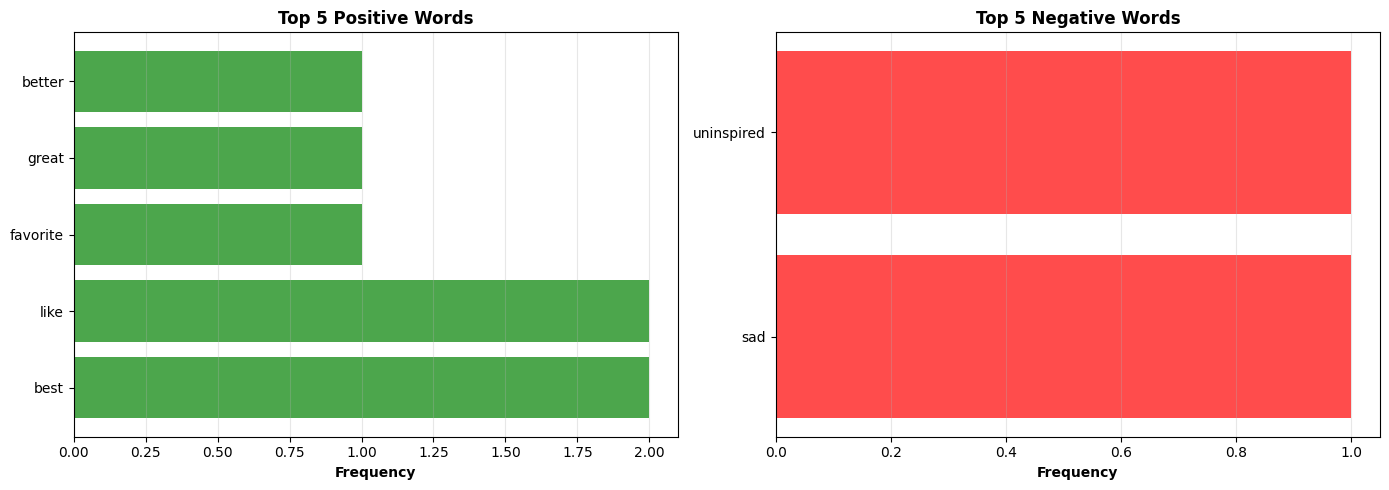


SUMMARY:
Total positive sentiment words found: 15
Total negative sentiment words found: 2
Unique positive words: 13
Unique negative words: 2

Positive/Negative word ratio: 7.50


In [ ]:
positive_words = []
negative_words = []

for review in reviews:
    tokens = preprocess_text(review, remove_stopwords=True)

    for token in tokens:
        score = afinn.score(token)
        if score > 0:
            positive_words.append(token)
        elif score < 0:
            negative_words.append(token)

# count frequencies
positive_counter = Counter(positive_words)
negative_counter = Counter(negative_words)

# get top 5 positive and top 5 negative
top_positive = positive_counter.most_common(5)
top_negative = negative_counter.most_common(5)

# display results with scores
print("Top 5 Positive Words:")
print("=" * 60)
print(f"{'Word':<15} {'AFINN Score':<15} {'Frequency':<15}")
print("-" * 60)
for word, count in top_positive:
    score = afinn.score(word)
    print(f"{word:<15} {score:<15} {count:<15}")

print("\nTop 5 Negative Words:")
print("=" * 60)
print(f"{'Word':<15} {'AFINN Score':<15} {'Frequency':<15}")
print("-" * 60)
for word, count in top_negative:
    score = afinn.score(word)
    print(f"{word:<15} {score:<15} {count:<15}")

# create bar chart visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# positive words chart
pos_words = [w for w, c in top_positive]
pos_counts = [c for w, c in top_positive]
ax1.barh(pos_words, pos_counts, color='green', alpha=0.7)
ax1.set_xlabel('Frequency', fontweight='bold')
ax1.set_title('Top 5 Positive Words', fontweight='bold', fontsize=12)
ax1.grid(axis='x', alpha=0.3)

# Negative words chart
neg_words = [w for w, c in top_negative]
neg_counts = [c for w, c in top_negative]
ax2.barh(neg_words, neg_counts, color='red', alpha=0.7)
ax2.set_xlabel('Frequency', fontweight='bold')
ax2.set_title('Top 5 Negative Words', fontweight='bold', fontsize=12)
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print("\n" + "="*60)
print("SUMMARY:")
print("="*60)
print(f"Total positive sentiment words found: {len(positive_words)}")
print(f"Total negative sentiment words found: {len(negative_words)}")
print(f"Unique positive words: {len(set(positive_words))}")
print(f"Unique negative words: {len(set(negative_words))}")
print(f"\nPositive/Negative word ratio: {len(positive_words)/len(negative_words):.2f}")

(c) Identify two specific limitations of lexicon-based sentiment analysis that are evident
in your results (e.g., negation, sarcasm, domain mismatch). For each limitation,
provide a concrete example from your data and suggest a mitigation strategy

This approach had the inability to handle negation, or semantic context. Review #3 "Not the best idea for a Spiderman movie," was marked as positive and didn't account for the preceding term "Not." To mitigate this, we have to implement a negative detection preporcessing rule to conver "best" to "not_best"

Also, letterboxd has a lot of slang. So I would porbably get the dataset from Rotten Tomantos or IMDB.

## Bonus Problem

## 6. Integrating Modules 4–6: End-to-End Pipeline

Choose a substantive political or social dataset (e.g., U.S. Congressional speeches, the
UN General Debate corpus, or a scraped collection of op-eds on a contested topic). Build
a complete analysis pipeline that integrates the three modules as follows

(a)  Pre-processing and TF-IDF [Module 4]. Pre-process the corpus with spaCy
(lowercase, remove stop words, lemmatize). Build a TF-IDF matrix and identify the
top-10 most distinctive terms for at least two document sub-groups of your choice
(e.g., party, year, or region

In [ ]:
import kagglehub

# https://www.kaggle.com/datasets/imuhammad/us-2020-presidential-election-speeches
path = kagglehub.dataset_download("imuhammad/us-2020-presidential-election-speeches")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'us-2020-presidential-election-speeches' dataset.
Path to dataset files: /kaggle/input/us-2020-presidential-election-speeches


In [ ]:
import os
import pandas as pd
import numpy as np
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer

dataset_dir = "/kaggle/input/us-2020-presidential-election-speeches"
csv_file = [f for f in os.listdir(dataset_dir) if f.endswith('.csv')][0]
df_speeches = pd.read_csv(os.path.join(dataset_dir, csv_file))

print("Dataset Columns:", df_speeches.columns.tolist())
print(df_speeches['speaker'].value_counts())

df_filtered = df_speeches[df_speeches['speaker'].isin(['Donald Trump', 'Joe Biden'])].copy()

# spaCy
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def spacy_preprocess(text):
    if not isinstance(text, str):
        return ""
    doc = nlp(text.lower())
    tokens = [token.lemma_ for token in doc if not token.is_stop and token.is_alpha and len(token.lemma_) > 2]
    return " ".join(tokens)

print("\nPre-processing text, this might take a moment...")
df_filtered['cleaned_text'] = df_filtered['text'].apply(spacy_preprocess)

grouped_docs = df_filtered.groupby('speaker')['cleaned_text'].apply(lambda x: " ".join(x)).reset_index()

vectorizer = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer.fit_transform(grouped_docs['cleaned_text'])
feature_names = vectorizer.get_feature_names_out()

print("\n" + "="*60)
print("TOP 10 MOST DISTINCTIVE TERMS PER SPEAKER (TF-IDF)")
print("="*60)

for i, row in grouped_docs.iterrows():
    speaker_name = row['speaker']
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = np.argsort(scores)[::-1][:10]

    print(f"\nSpeaker: {speaker_name}")
    print("-" * 30)
    for idx in top_indices:
        print(f"{feature_names[idx]:<20} (TF-IDF: {scores[idx]:.4f})")

Dataset Columns: ['speaker', 'title', 'text', 'date', 'location', 'type']
speaker
Joe Biden                                 71
Donald Trump                              53
Mike Pence                                19
Bernie Sanders                            16
Kamala Harris                             11
                                          ..
Joe Biden, Al Gore                         1
Joe Biden, Bernie Sanders                  1
Tulsi Gabbard                              1
Donna Brazile                              1
Pete Buttigieg,Amy Klobuchar, O’Rourke     1
Name: count, Length: 71, dtype: int64

Pre-processing text, this might take a moment...

TOP 10 MOST DISTINCTIVE TERMS PER SPEAKER (TF-IDF)

Speaker: Donald Trump
------------------------------
trump                (TF-IDF: 0.3987)
donald               (TF-IDF: 0.3307)
say                  (TF-IDF: 0.2563)
people               (TF-IDF: 0.2241)
great                (TF-IDF: 0.2190)
know                 (TF-IDF: 0.2146)
w

(b) Similarity and Clustering [Module 5]. Compute pairwise cosine similarity and
run K-Means (justify your choice of K). Visualise the clusters using a 2-D PCA
projection. Do the clusters correspond to the sub-groups identified in part (a)?
Discuss

Cosine Similarity Matrix Shape: (124, 124)
Average Pairwise Cosine Similarity: 0.3484


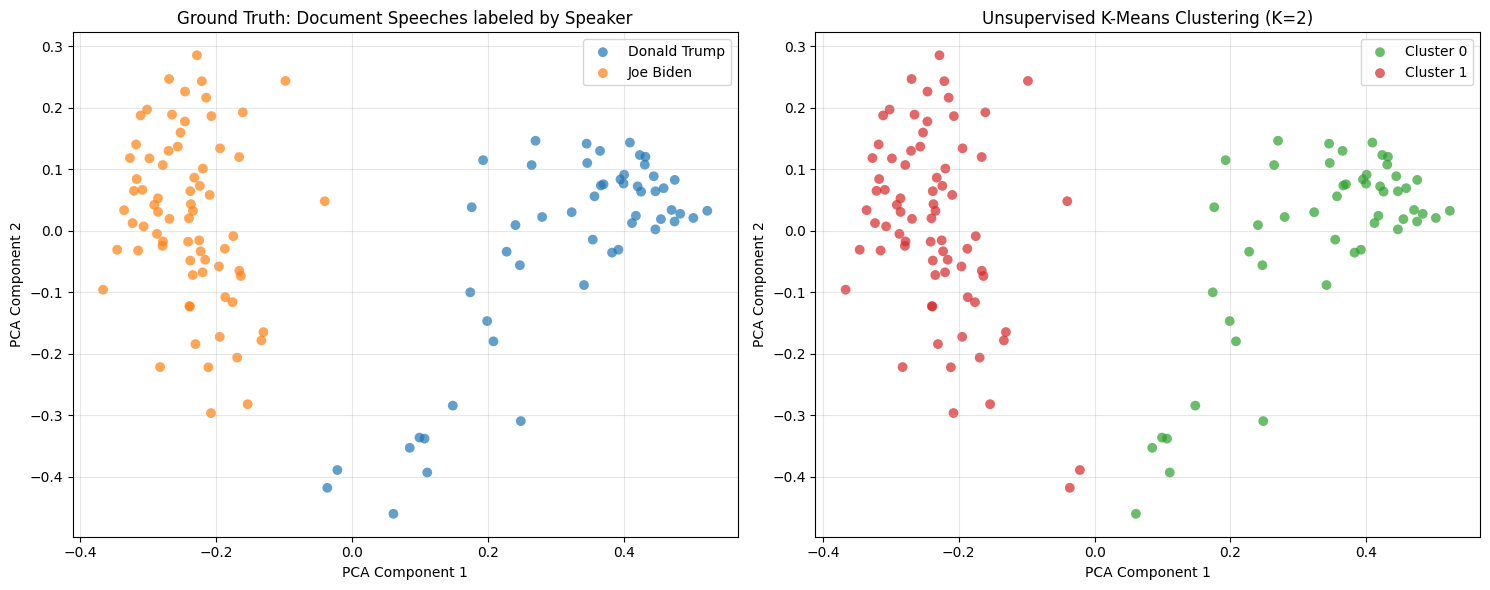


Alignment Crosstab (Speakers vs. Clusters):
cluster        0   1
speaker             
Donald Trump  51   2
Joe Biden      0  71


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

vectorizer_ind = TfidfVectorizer(max_features=5000, stop_words='english')
X_ind = vectorizer_ind.fit_transform(df_filtered['cleaned_text'])

cos_sim = cosine_similarity(X_ind)
print(f"Cosine Similarity Matrix Shape: {cos_sim.shape}")
print(f"Average Pairwise Cosine Similarity: {cos_sim.mean():.4f}")

K = 2
km = KMeans(n_clusters=K, random_state=42, n_init=20)
cluster_labels = km.fit_predict(X_ind)
df_filtered['cluster'] = cluster_labels

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_ind.toarray())

df_filtered['pca1'] = X_pca[:, 0]
df_filtered['pca2'] = X_pca[:, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors_speaker = {'Donald Trump': '#1f77b4', 'Joe Biden': '#ff7f0e'}
for speaker, group in df_filtered.groupby('speaker'):
    ax1.scatter(group['pca1'], group['pca2'], label=speaker, alpha=0.7, edgecolors='none', s=50,
                color=colors_speaker[speaker])
ax1.set_title("Ground Truth: Document Speeches labeled by Speaker")
ax1.set_xlabel("PCA Component 1")
ax1.set_ylabel("PCA Component 2")
ax1.legend()
ax1.grid(True, alpha=0.3)

colors_cluster = {0: '#2ca02c', 1: '#d62728'}
for cluster, group in df_filtered.groupby('cluster'):
    ax1_color = colors_cluster[cluster]
    ax2.scatter(group['pca1'], group['pca2'], label=f"Cluster {cluster}", alpha=0.7, edgecolors='none', s=50,
                color=ax1_color)
ax2.set_title(f"Unsupervised K-Means Clustering (K={K})")
ax2.set_xlabel("PCA Component 1")
ax2.set_ylabel("PCA Component 2")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

crosstab = pd.crosstab(df_filtered['speaker'], df_filtered['cluster'])
print("\nAlignment Crosstab (Speakers vs. Clusters):")
print("="*50)
print(crosstab)

Yes, the unsupervised clusters correspond well to the candidate subgroups. 2 out of the 124 speeches from Donald Trump were "missclassified" to the other candidate's cluster, meaning that the patterns used by Trump and Biden are very distinct (vocab, rhetorical patterns, etc).

(c) Sentiment Over Time [Module 6]. Apply a sentiment lexicon of your choice
to the corpus. Aggregate sentiment by a meaningful time unit or group and plot
the trajectory. Formulate and evaluate at least two a priori hypotheses about the
expected sentiment patterns, following the approach modelled in the Jane Austen
example from the lecture.


1. **Hypothesis 1**: Joe Biden's speeches will demonstrate more positive sentiment trajectories over time than Donald Trump's.
2. **Hypothesis 2**: Both candidates will display a downward trend in sentiment as Election Day (November 2020) approaches

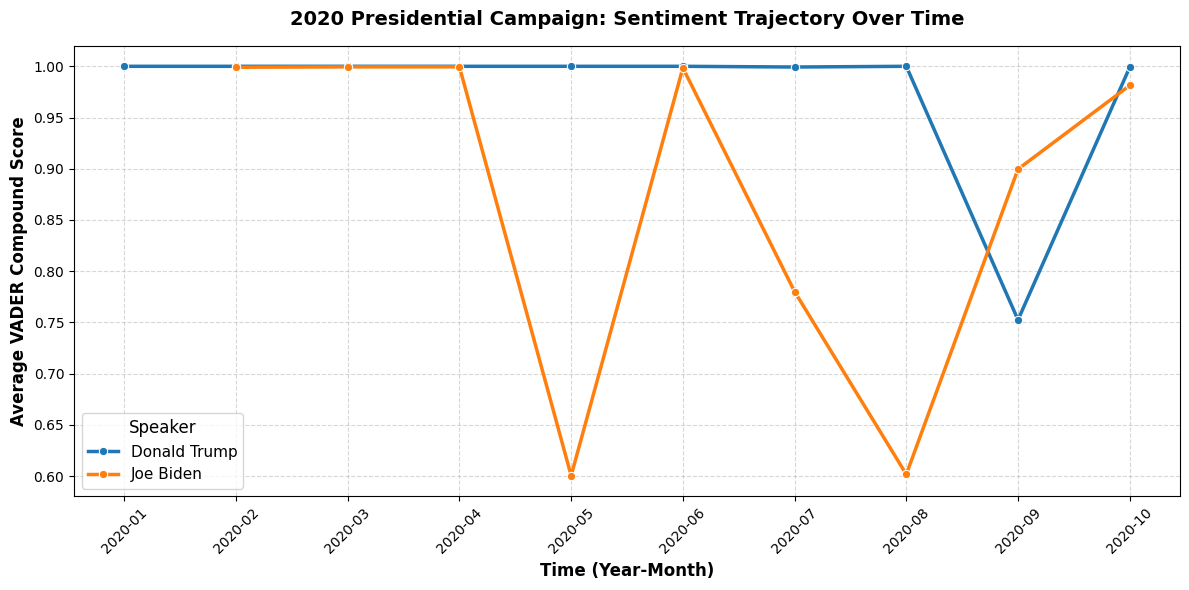

speaker,Donald Trump,Joe Biden
year_month_str,,
2020-01,1.000000,NaN
2020-02,1.000000,0.999067
2020-03,1.000000,0.999443
2020-04,NaN,0.999475
2020-05,1.000000,0.600420
2020-06,1.000000,0.998475
2020-07,0.999300,0.780133
2020-08,1.000000,0.601720
2020-09,0.752542,0.899610


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

df_filtered['date_parsed'] = pd.to_datetime(df_filtered['date'], errors='coerce')
df_sentiment = df_filtered.dropna(subset=['date_parsed', 'text']).copy()

df_sentiment['year_month'] = df_sentiment['date_parsed'].dt.to_period('M')

df_sentiment['vader_compound'] = df_sentiment['text'].apply(lambda x: sia.polarity_scores(x)['compound'])

monthly_sentiment = df_sentiment.groupby(['speaker', 'year_month'])['vader_compound'].mean().reset_index()
monthly_sentiment['year_month_str'] = monthly_sentiment['year_month'].astype(str)

monthly_sentiment = monthly_sentiment.sort_values('year_month')

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_sentiment,
    x='year_month_str',
    y='vader_compound',
    hue='speaker',
    marker='o',
    linewidth=2.5,
    palette={'Donald Trump': '#1f77b4', 'Joe Biden': '#ff7f0e'}
)

plt.title("2020 Presidential Campaign: Sentiment Trajectory Over Time", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Time (Year-Month)", fontsize=12, fontweight='bold')
plt.ylabel("Average VADER Compound Score", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Speaker", fontsize=11, title_fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sentiment.pivot(index='year_month_str', columns='speaker', values='vader_compound'))

**Evaluation 1:** Donald Trump's avg compound sentiment score remained saturated at 1.000 for 7/9 months, exceeding Biden's sentiment scores.

**Evaluation 2:** Both candidates noticed drops during campaign polarization, they recovered in October 2020.